In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import KFold
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import GridSearchCV


!pip install catboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier,CatBoostRegressor
import time
from sklearn.model_selection import learning_curve
from sklearn.model_selection import ShuffleSplit

from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef, cohen_kappa_score
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.model_selection import cross_val_predict
import warnings
warnings.filterwarnings("ignore")


# data prepartipon

In [ ]:
def prepare_target_feature(unitig_file_path, metadata_file_path, target_column):
    """
    Prepares the target and feature datasets for a given antibiotic resistance data.

    Parameters:
    - unitig_file_path: Path to the unitig file (sequence data)
    - metadata_file_path: Path to the metadata file
    - target_column: The target column in the metadata file (e.g., 'cip_sr')

    Returns:
    - feature: The feature dataset (aligned sequence data)
    - target: The target dataset (binary)
    """
    # Load the sequence (unitig) data
    sequence_data = pd.read_csv(unitig_file_path, sep=" ", index_col=0, low_memory=False)

    # Transpose the sequence data
    sequence_data_transposed = sequence_data.transpose()

    # Load the metadata
    metadata = pd.read_csv(metadata_file_path, index_col=0)

    # Drop rows with null values in the target column
    cleaned_metadata = metadata.dropna(subset=[target_column])

    # Convert the target column to binary: Sensitive=0, Resistant=1
    cleaned_metadata[f'{target_column}_binary'] = cleaned_metadata[target_column].map({'Sensitive': 0, 'Resistant': 1})

    # Keep only the binary target column
    target_data = cleaned_metadata[[f'{target_column}_binary']]

    # Align the sequence data index with the target dataset index
    aligned_sequence_data = sequence_data_transposed[sequence_data_transposed.index.isin(target_data.index)]

    # Align the target data index with the sequence dataset index
    aligned_target_data = target_data[target_data.index.isin(aligned_sequence_data.index)]

    # Convert the target data to a Series
    target = aligned_target_data.squeeze()

    # The feature dataset is the aligned sequence data
    feature = aligned_sequence_data

    return target, feature, cleaned_metadata

In [ ]:
#return target, ferature and cleaned_metadata
target, feature, cleaned_metadata = prepare_target_feature('/content/azm_sr_gwas_filtered_unitigs.Rtab', '/content/metadata_remane_original.csv', 'azm_sr')

In [ ]:
print(feature.shape)
feature.tail(5)


(3650, 515)


pattern_id,CTTAACATATTTGCCTTTGATTTTTGAAGAAGCTGCCACGCCGGCAG,TACCGTAACCGGCAATGCGGATATTACGGTC,CAGACGGCATTTTTTTTGCGTTTTTCGGGAGG,AACGGGTTTTCAGACGGCATTCGATATCGGGACG,CCAAAAATTACCCGCGTTGACGTAGCTAAAGA,CGGACCGGTATTCCGTCGAAATCACCGCCGTCAACCGCCCC,TGAAATTGTCCATCTCGTATGCCGTCTTCTGCTTG,"TACGGTATTGTCCGCATTATTAAACTCAAAACC,AGAAGACGGCATACGAGATGGACAATTTCATCC",GGCATTTTTTTTGCGTTTTTCGGGAGGGGGCGGC,TATATAAGGGGTTGCCGTTCCGCAGTTGGGCGGCAGCATAC,...,ACCGATGAGTTCGCCGGAATCGGTACGATTGAC,CTGCTGGACAAAAAAGGGATTAAAGATATCACC,CGTTCCTTTCGGCGTATTCTCGCCGTTGCGCGGCG,TCACATTTCCGCTTCAGACGGCATCCGATATGA,GAAGCTGCCACGCCGGCAGAAGTGTTGTTTGCGGG,ACGCCGAAAGGAACGTGTATGCTGCCGCCCAACTGCG,ACTCGAATTTTGCAGGATTGGTATCAATGGCGATAATGCGACCGGCTTTGG,"ACCCGGCCCGGGCTGGCAGGCTACGGCTACACCGGTATCC,CACCTTAGGGAATCGTTCCCTTTGGGCCGGG,TACGCCGAAAGGAACGTGTATGCTGCCGCCC,GGGATTGTTGATTGTCGGACTGTTGTGCAACCTC",AGCCTGATTCACCAATGGTTTGTTCATAACAA,TTTTGAGCAGAAAGCAGTCAAAAACAGGGGGATTTTGCCCTTTTGACAGGTTCGAGTGCCG
ERR2172350,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
ERR2172351,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
ERR2172352,1,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
ERR2172353,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
ERR2172354,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1


In [ ]:
print(target.shape)
print(target.head(5))



(3650,)
ID
11791_8#10    0
11791_8#11    0
11791_8#12    0
11791_8#13    0
11791_8#14    0
Name: azm_sr_binary, dtype: int64


# ------Fit Model Funciton with Cross Validation and Grid Search-------------

In [ ]:

# function for fitting a model
performance = []
method = []
times = []
scores=[]

def fitmodel(X, pheno, estimator, parameters, modelname, method, performance, times) :

    kfold = KFold(n_splits=5)
    kfold_id = 0
    for train_index, test_index in kfold.split(X, pheno):
        # time how long it takes to train each model type
        start = time.process_time()

        # split data into train/test sets
        X_train = X.iloc[train_index]
        y_train = pheno[train_index]
        X_test = X.iloc[test_index]
        y_test = pheno[test_index]

        # perform grid search to identify best hyper-parameters
        gs_clf = GridSearchCV(estimator=estimator, param_grid=parameters, cv=3, n_jobs=-1, scoring='balanced_accuracy')
        gs_clf.fit(X_train, y_train)

        # predict resistance in test set
        y_pred = gs_clf.predict(X_test)
        y_pred_prob = gs_clf.predict_proba(X_test)[:, 1]

        # call all samples with a predicted value less than or equal to 0.5 as sensitive to the antibiotic,
        # and samples with predicted value >0.5 resistant to the antibiotic
        y_pred[y_pred<=0.5] = 0
        y_pred[y_pred>0.5] = 1

        # Calculate performance metrics
        accuracy = accuracy_score(y_test, y_pred)
        balance_accuracy = balanced_accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)
        kappa = cohen_kappa_score(y_test, y_pred)
        auc_roc = roc_auc_score(y_test, y_pred_prob)
        confusionMatrix = confusion_matrix(y_test, y_pred)
        classificationReport = classification_report(y_test, y_pred)

        # Store performance metrics for later analysis
        performance = np.append(performance, balance_accuracy)
        method = np.append(method, modelname)
        times = np.append(times, (time.process_time() - start))

        # Append metrics to the scores list
        scores.append({
            'model': modelname,
            'fold': kfold_id,
            'accuracy': accuracy,
            'balanced_accuracy': balance_accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'mcc': mcc,
            'kappa': kappa,
            'roc_auc': auc_roc,
            'confusion_matrix': confusionMatrix,
            'classification_report': classificationReport
        })
        print(f'\n{modelname} kfold={kfold_id}')
        print(f'{gs_clf.best_params_}')
        print(f'balance acuracy={balance_accuracy}')
        print("Confusion matrix")
        print(confusionMatrix)
        print('classification_report')
        print(classificationReport)
        kfold_id=kfold_id+1
    print(f'----end {modelname} -------')
    return gs_clf, method, performance, times, scores

In [ ]:
#setting feature and target variable
X=feature
y=target

# --------Fitting Model and Print Measurement Metrics ----------

# --------------SVM Classifier------------

In [ ]:
#model fit with SMV Classifier
svm = SVC(class_weight='balanced', probability=True)
svm_params = {
    'C': [0.01],
    'gamma': [1e-06, 1e-05],
    'kernel': ['linear', 'rbf', 'sigmoid'],
    'class_weight': ['balanced']
}

svm_model, method, performance, times, scores = fitmodel(X, y, svm, svm_params, "Support vector machine", method, performance, times)


Support vector machine kfold=0
{'C': 0.01, 'class_weight': 'balanced', 'gamma': 1e-06, 'kernel': 'linear'}
balance acuracy=0.8084250018212282
Confusion matrix
[[515   3]
 [ 80 132]]
classification_report
              precision    recall  f1-score   support

           0       0.87      0.99      0.93       518
           1       0.98      0.62      0.76       212

    accuracy                           0.89       730
   macro avg       0.92      0.81      0.84       730
weighted avg       0.90      0.89      0.88       730


Support vector machine kfold=1
{'C': 0.01, 'class_weight': 'balanced', 'gamma': 1e-06, 'kernel': 'linear'}
balance acuracy=0.8992418196328811
Confusion matrix
[[674  42]
 [  2  12]]
classification_report
              precision    recall  f1-score   support

           0       1.00      0.94      0.97       716
           1       0.22      0.86      0.35        14

    accuracy                           0.94       730
   macro avg       0.61      0.90      0.66  

In [ ]:
# best_model = svm_model.best_estimator_
# print(svm_model.cv_results_['split0_test_score'])

# -------------------------CATBOOST-------------------

In [ ]:
#model fit with CatBoost Classifier
cat_params = {'n_estimators':[10,25,40],
         'learning_rate':[0.01,0.05,0.5]}
catboost=CatBoostClassifier(silent=True,task_type="CPU")
cat_model, method, performance, times, scores = fitmodel(X, y, catboost, cat_params, "Cat Boost", method, performance, times)


Cat Boost kfold=0
{'learning_rate': 0.5, 'n_estimators': 10}
balance acuracy=0.8131419829533038
Confusion matrix
[[515   3]
 [ 78 134]]
classification_report
              precision    recall  f1-score   support

           0       0.87      0.99      0.93       518
           1       0.98      0.63      0.77       212

    accuracy                           0.89       730
   macro avg       0.92      0.81      0.85       730
weighted avg       0.90      0.89      0.88       730


Cat Boost kfold=1
{'learning_rate': 0.5, 'n_estimators': 40}
balance acuracy=0.8200319233838786
Confusion matrix
[[714   2]
 [  5   9]]
classification_report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       716
           1       0.82      0.64      0.72        14

    accuracy                           0.99       730
   macro avg       0.91      0.82      0.86       730
weighted avg       0.99      0.99      0.99       730


Cat Boost kfold=2
{'learnin

# ------------RandomForest Classifier---------------

In [ ]:
#model fit with RandomForest Classifier
rf = RandomForestClassifier(random_state=0, n_jobs=-1, class_weight="balanced")
rf_params = {
    'max_features': [round(X.shape[1]*0.1), round(X.shape[1]*0.5), round(X.shape[1]*0.8)],
    'max_depth': [3],
    'n_estimators': [50]
}

rf_model, method, performance, times, scores = fitmodel(X, y, rf, rf_params, "Random forest", method, performance, times)


Random forest kfold=0
{'max_depth': 3, 'max_features': 52, 'n_estimators': 50}
balance acuracy=0.7615647993006484
Confusion matrix
[[486  32]
 [ 88 124]]
classification_report
              precision    recall  f1-score   support

           0       0.85      0.94      0.89       518
           1       0.79      0.58      0.67       212

    accuracy                           0.84       730
   macro avg       0.82      0.76      0.78       730
weighted avg       0.83      0.84      0.83       730


Random forest kfold=1
{'max_depth': 3, 'max_features': 52, 'n_estimators': 50}
balance acuracy=0.752294493216281
Confusion matrix
[[617  99]
 [  5   9]]
classification_report
              precision    recall  f1-score   support

           0       0.99      0.86      0.92       716
           1       0.08      0.64      0.15        14

    accuracy                           0.86       730
   macro avg       0.54      0.75      0.53       730
weighted avg       0.97      0.86      0.91     

# ------------------XGB Classifier-------------

In [ ]:
#model fit with XGB Classifier
xgb_mod = XGBClassifier(random_state=0)
xgb_params = {
    'alpha': [1e-5, 1e-4],
    'gamma': [0.05, 0.1],
    'learning_rate': [0.01, 0.1],
    'max_depth': [2],
    'colsample_bytree': [0.6],
    'subsample': [0.2, 0.4, 0.6],
    'objective': ['binary:hinge']
}

xgb_model, method, performance, times, scores = fitmodel(X, y, xgb_mod, xgb_params, "XGBoost", method, performance, times)


XGBoost kfold=0
{'alpha': 1e-05, 'colsample_bytree': 0.6, 'gamma': 0.05, 'learning_rate': 0.1, 'max_depth': 2, 'objective': 'binary:hinge', 'subsample': 0.6}
balance acuracy=0.8093902527864791
Confusion matrix
[[516   2]
 [ 80 132]]
classification_report
              precision    recall  f1-score   support

           0       0.87      1.00      0.93       518
           1       0.99      0.62      0.76       212

    accuracy                           0.89       730
   macro avg       0.93      0.81      0.84       730
weighted avg       0.90      0.89      0.88       730


XGBoost kfold=1
{'alpha': 1e-05, 'colsample_bytree': 0.6, 'gamma': 0.05, 'learning_rate': 0.1, 'max_depth': 2, 'objective': 'binary:hinge', 'subsample': 0.2}
balance acuracy=0.8214285714285714
Confusion matrix
[[716   0]
 [  5   9]]
classification_report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       716
           1       1.00      0.64      0.78        1

#------------ **Feature Important---------------------**

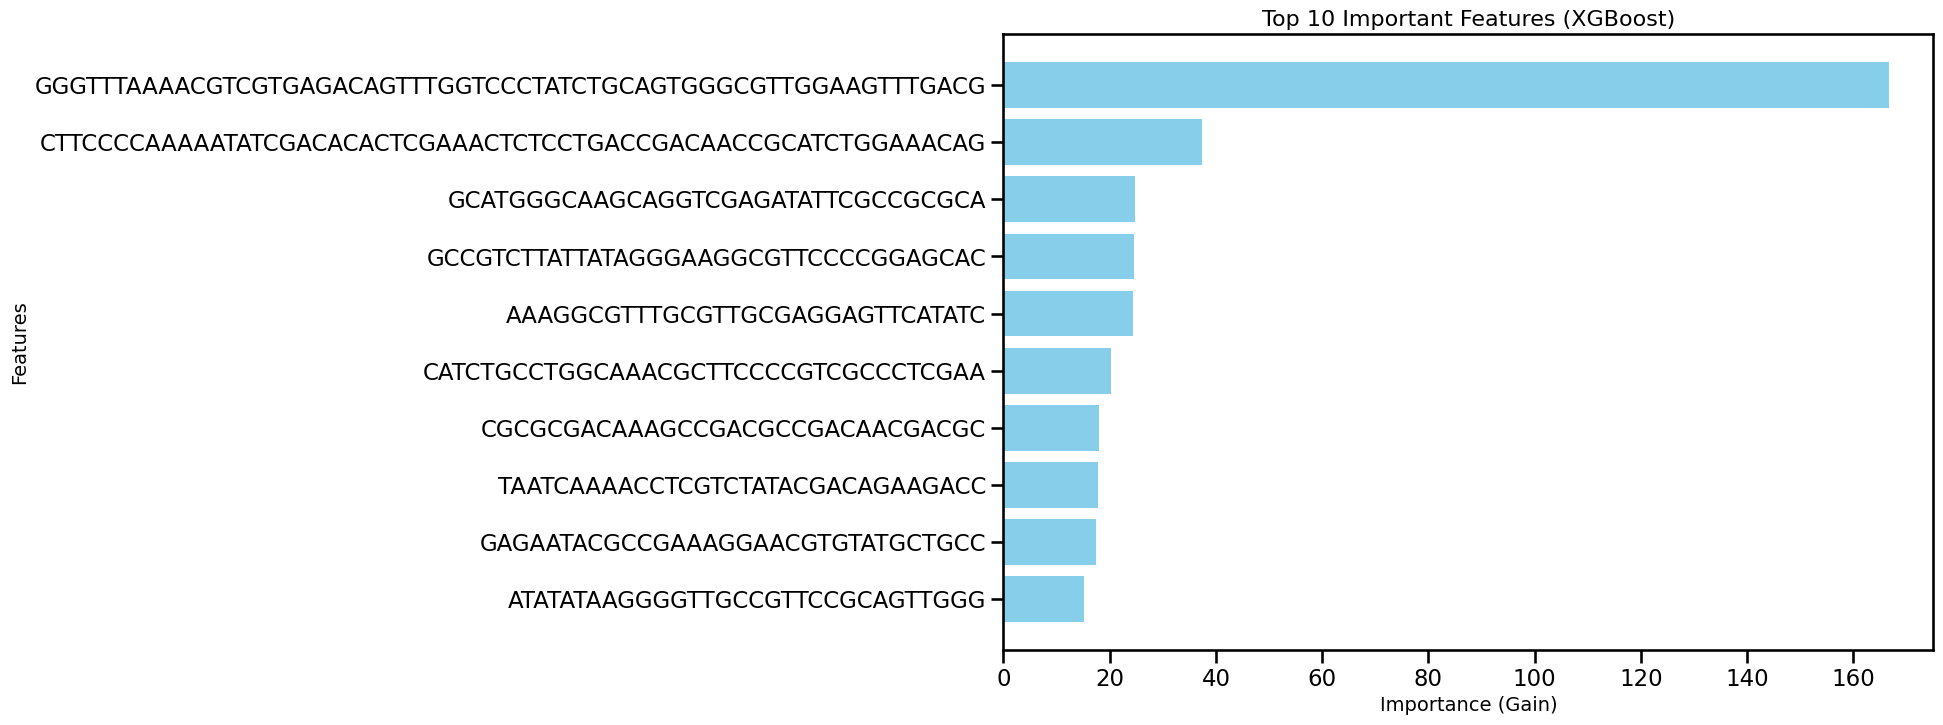

In [ ]:
#xgb boost

booster = xgb_model.best_estimator_.get_booster()

# Get feature importance by gain
importance_by_gain = booster.get_score(importance_type='gain')

# Convert to a sorted list (sorted by gain in descending order)
importance_sorted = sorted(importance_by_gain.items(), key=lambda x: x[1], reverse=True)

# Extract the top 10 features and their importance
top_features = importance_sorted[:10]

features, importances = zip(*top_features)

# Plot
plt.figure(figsize=(12, 8))
plt.barh(features, importances, align='center', color='skyblue')
plt.xlabel('Importance (Gain)', fontsize=14)
plt.ylabel('Features', fontsize=14)
plt.title('Top 10 Important Features (XGBoost)', fontsize=16)
plt.gca().invert_yaxis()  # Invert y-axis to have the most important feature on top
plt.show()

In [ ]:
for feature, importance in top_features:
    print(f"Feature: {feature}, Importance (Gain): {importance}")

Feature: GGGTTTAAAACGTCGTGAGACAGTTTGGTCCCTATCTGCAGTGGGCGTTGGAAGTTTGACG, Importance (Gain): 166.72972106933594
Feature: CTTCCCCAAAAATATCGACACACTCGAAACTCTCCTGACCGACAACCGCATCTGGAAACAG, Importance (Gain): 37.47147750854492
Feature: GCATGGGCAAGCAGGTCGAGATATTCGCCGCGCA, Importance (Gain): 24.7278995513916
Feature: GCCGTCTTATTATAGGGAAGGCGTTCCCCGGAGCAC, Importance (Gain): 24.4918270111084
Feature: AAAGGCGTTTGCGTTGCGAGGAGTTCATATC, Importance (Gain): 24.449813842773438
Feature: CATCTGCCTGGCAAACGCTTCCCCGTCGCCCTCGAA, Importance (Gain): 20.17288589477539
Feature: CGCGCGACAAAGCCGACGCCGACAACGACGC, Importance (Gain): 17.93109130859375
Feature: TAATCAAAACCTCGTCTATACGACAGAAGACC, Importance (Gain): 17.759809494018555
Feature: GAGAATACGCCGAAAGGAACGTGTATGCTGCC, Importance (Gain): 17.371383666992188
Feature: ATATATAAGGGGTTGCCGTTCCGCAGTTGGG, Importance (Gain): 15.076894760131836


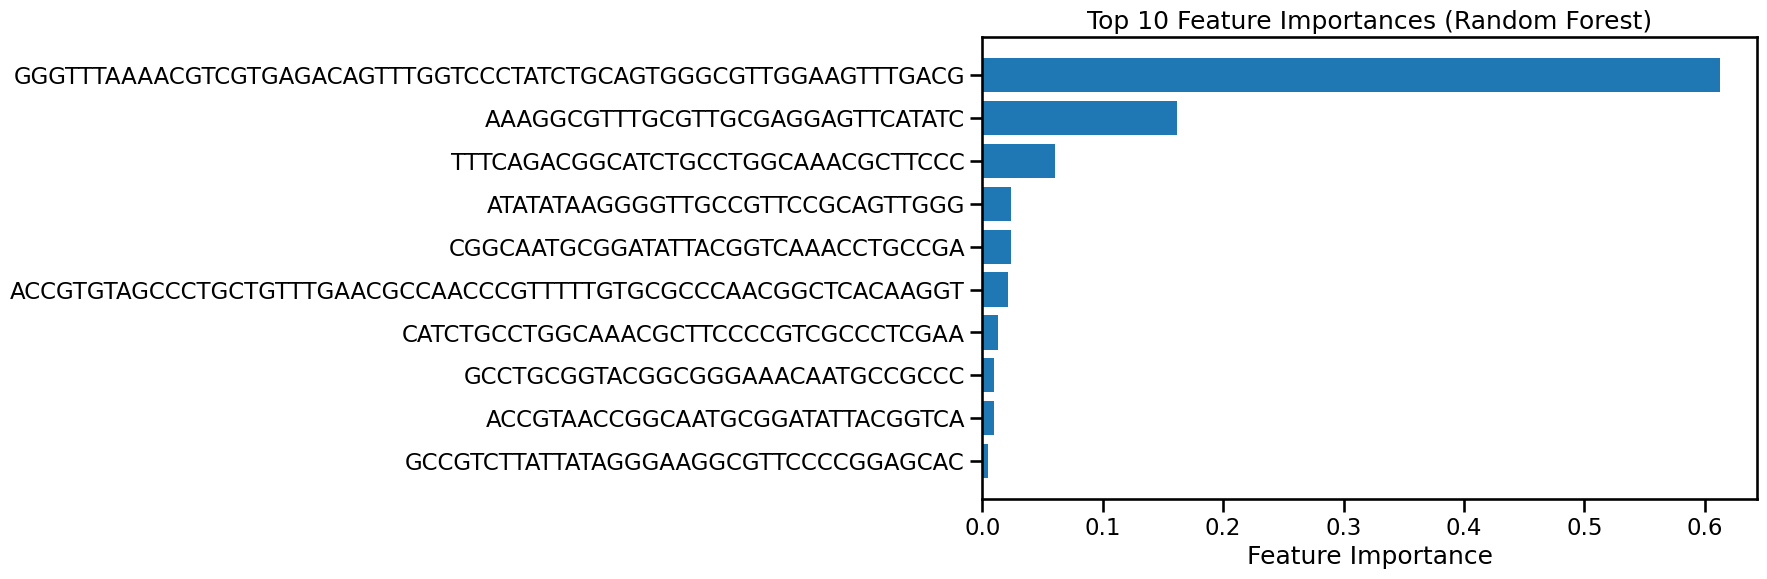

Top 10 Most Important Features:
Feature: GGGTTTAAAACGTCGTGAGACAGTTTGGTCCCTATCTGCAGTGGGCGTTGGAAGTTTGACG, Importance: 0.6129076000814104
Feature: AAAGGCGTTTGCGTTGCGAGGAGTTCATATC, Importance: 0.16146196821253334
Feature: TTTCAGACGGCATCTGCCTGGCAAACGCTTCCC, Importance: 0.06067222148056404
Feature: ATATATAAGGGGTTGCCGTTCCGCAGTTGGG, Importance: 0.023932419582362297
Feature: CGGCAATGCGGATATTACGGTCAAACCTGCCGA, Importance: 0.023768996056380037
Feature: ACCGTGTAGCCCTGCTGTTTGAACGCCAACCCGTTTTTGTGCGCCCAACGGCTCACAAGGT, Importance: 0.02132488802062065
Feature: CATCTGCCTGGCAAACGCTTCCCCGTCGCCCTCGAA, Importance: 0.013360122678661311
Feature: GCCTGCGGTACGGCGGGAAACAATGCCGCCC, Importance: 0.009866182869365107
Feature: ACCGTAACCGGCAATGCGGATATTACGGTCA, Importance: 0.009713384660418557
Feature: GCCGTCTTATTATAGGGAAGGCGTTCCCCGGAGCAC, Importance: 0.005109495623351556


In [ ]:
# Extract feature importances from the Random Forest model
importances = rf_model.best_estimator_.feature_importances_

# Get the feature names
feature_names = X.columns

# Sort the feature importances and get the indices
indices = np.argsort(importances)[::-1]

# Top 10 features
top_10_indices = indices[:10]

# Plot the top 10 feature importances
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances (Random Forest)")
plt.barh(range(len(top_10_indices)), importances[top_10_indices], align="center")
plt.yticks(range(len(top_10_indices)), [feature_names[i] for i in top_10_indices])
plt.xlabel("Feature Importance")
plt.gca().invert_yaxis()  # Invert y-axis to have the most important feature at the top
plt.show()

# Print the top 10 features and their importance scores
print("Top 10 Most Important Features:")
for i in top_10_indices:
    print(f"Feature: {feature_names[i]}, Importance: {importances[i]}")

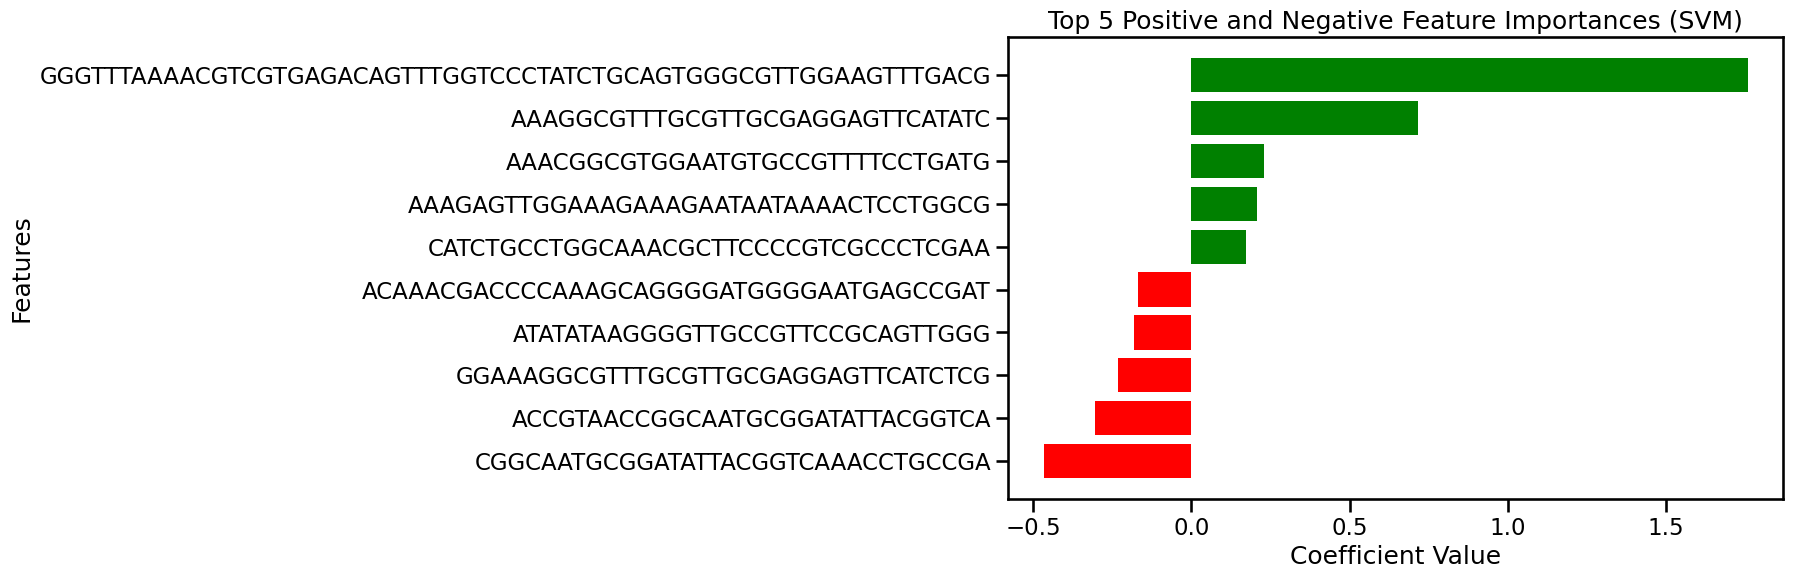

Top 5 Positive Features:
Feature: CATCTGCCTGGCAAACGCTTCCCCGTCGCCCTCGAA, Coefficient: 0.17095322218422812
Feature: AAAGAGTTGGAAAGAAAGAATAATAAAACTCCTGGCG, Coefficient: 0.20705240585149956
Feature: AAACGGCGTGGAATGTGCCGTTTTCCTGATG, Coefficient: 0.22793262011449988
Feature: AAAGGCGTTTGCGTTGCGAGGAGTTCATATC, Coefficient: 0.7169666096858702
Feature: GGGTTTAAAACGTCGTGAGACAGTTTGGTCCCTATCTGCAGTGGGCGTTGGAAGTTTGACG, Coefficient: 1.7602266735431296

Top 5 Negative Features:
Feature: CGGCAATGCGGATATTACGGTCAAACCTGCCGA, Coefficient: -0.46742589296395354
Feature: ACCGTAACCGGCAATGCGGATATTACGGTCA, Coefficient: -0.303678415599688
Feature: GGAAAGGCGTTTGCGTTGCGAGGAGTTCATCTCG, Coefficient: -0.23372158158037104
Feature: ATATATAAGGGGTTGCCGTTCCGCAGTTGGG, Coefficient: -0.18244060760608138
Feature: ACAAACGACCCCAAAGCAGGGGATGGGGAATGAGCCGAT, Coefficient: -0.16833140342472275


In [ ]:
# Extract feature importances from the Support vectore model
coefficients = svm_model.best_estimator_.coef_.ravel()

# Get the feature names
feature_names = X.columns

# Sort the coefficients and get the indices of the top 5 positive and top 5 negative features
top_positive_indices = np.argsort(coefficients)[-5:]  # Top 5 positive
top_negative_indices = np.argsort(coefficients)[:5]   # Top 5 negative

# Get the feature names and corresponding coefficients for the top features
top_positive_features = [(feature_names[i], coefficients[i]) for i in top_positive_indices]
top_negative_features = [(feature_names[i], coefficients[i]) for i in top_negative_indices]

# Combine and sort them for plotting
top_features = top_negative_features + top_positive_features
top_features_sorted = sorted(top_features, key=lambda x: x[1])

# Plot
feature_names_sorted, coefficients_sorted = zip(*top_features_sorted)

plt.figure(figsize=(10, 6))
plt.barh(feature_names_sorted, coefficients_sorted, color=['red']*5 + ['green']*5)
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.title('Top 5 Positive and Negative Feature Importances (SVM)')
plt.show()

# Print the top 5 positive and top 5 negative features
print("Top 5 Positive Features:")
for feature, coef in top_positive_features:
    print(f"Feature: {feature}, Coefficient: {coef}")

print("\nTop 5 Negative Features:")
for feature, coef in top_negative_features:
    print(f"Feature: {feature}, Coefficient: {coef}")

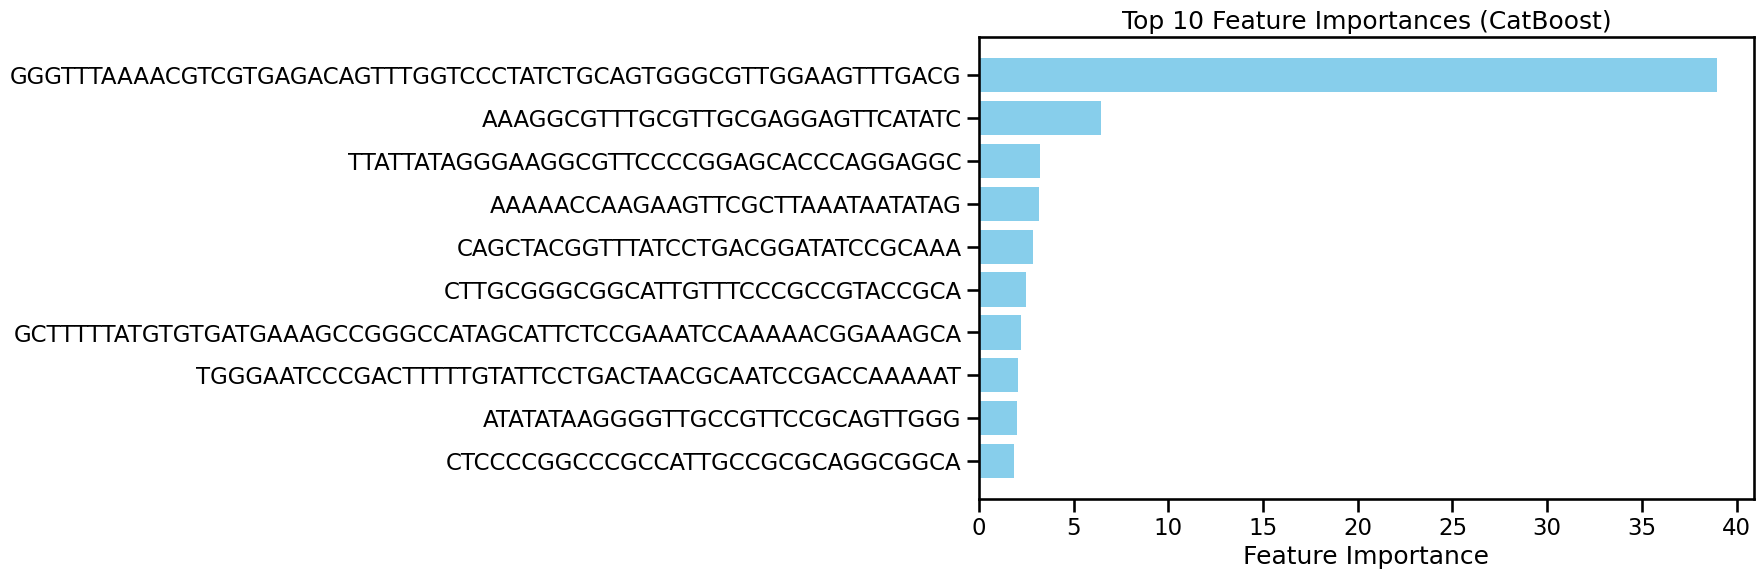

Top 10 Most Important Features:
Feature: GGGTTTAAAACGTCGTGAGACAGTTTGGTCCCTATCTGCAGTGGGCGTTGGAAGTTTGACG, Importance: 38.96190219836662
Feature: AAAGGCGTTTGCGTTGCGAGGAGTTCATATC, Importance: 6.421170060055687
Feature: TTATTATAGGGAAGGCGTTCCCCGGAGCACCCAGGAGGC, Importance: 3.236082746729491
Feature: AAAAACCAAGAAGTTCGCTTAAATAATATAG, Importance: 3.1895272005047537
Feature: CAGCTACGGTTTATCCTGACGGATATCCGCAAA, Importance: 2.8355333046229942
Feature: CTTGCGGGCGGCATTGTTTCCCGCCGTACCGCA, Importance: 2.4881714803187442
Feature: GCTTTTTATGTGTGATGAAAGCCGGGCCATAGCATTCTCCGAAATCCAAAAACGGAAAGCA, Importance: 2.2130357128015667
Feature: TGGGAATCCCGACTTTTTGTATTCCTGACTAACGCAATCCGACCAAAAAT, Importance: 2.080736414601139
Feature: ATATATAAGGGGTTGCCGTTCCGCAGTTGGG, Importance: 1.9965226084117729
Feature: CTCCCCGGCCCGCCATTGCCGCGCAGGCGGCA, Importance: 1.857802706017377


In [ ]:
# Extract feature importances from the Catboost model
importances = cat_model.best_estimator_.get_feature_importance()

# Get the feature names
feature_names = X.columns

# Sort the feature importances and get the indices
indices = np.argsort(importances)[::-1]

# Top 10 features
top_10_indices = indices[:10]

# Plot the top 10 feature importances
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances (CatBoost)")
plt.barh(range(len(top_10_indices)), importances[top_10_indices], align="center", color='skyblue')
plt.yticks(range(len(top_10_indices)), [feature_names[i] for i in top_10_indices])
plt.xlabel("Feature Importance")
plt.gca().invert_yaxis()  # Invert y-axis to have the most important feature at the top
plt.show()

# Print the top 10 features and their importance scores
print("Top 10 Most Important Features:")
for i in top_10_indices:
    print(f"Feature: {feature_names[i]}, Importance: {importances[i]}")

# ---------------------Model Comparison With ROC_AUC---------------

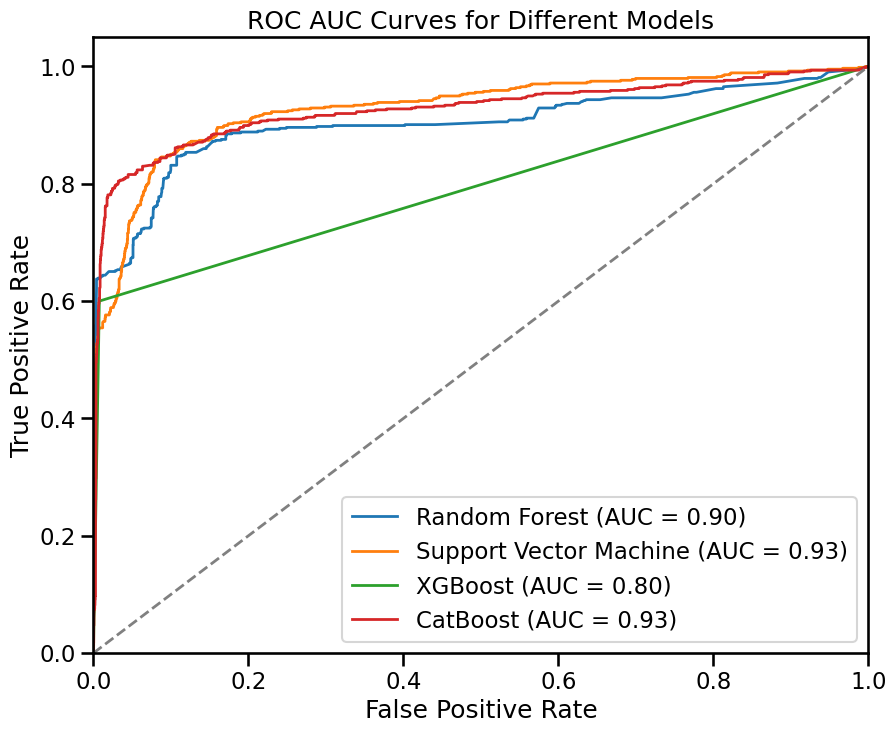

In [ ]:

# List of models and their names for comparison of ROC_AUC Curve with best estimator
models = [
    ('Random Forest', rf_model.best_estimator_),
    ('Support Vector Machine', svm_model.best_estimator_),
    ('XGBoost', xgb_model.best_estimator_),
    ('CatBoost', cat_model.best_estimator_)
]

plt.figure(figsize=(10, 8))

# Loop through each model to plot its ROC AUC
for model_name, model in models:
    # Get cross-validated predictions (probabilities)
    y_pred_prob = cross_val_predict(model, X, y, cv=5, method='predict_proba')[:, 1]

    # Compute ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

# Plot the diagonal line representing random guessing
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=2)

# Set plot limits and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC AUC Curves for Different Models')
plt.legend(loc="lower right")
plt.show()

# ------------Comarison Metrix OF ALL Model----------

In [ ]:
#metricts_df is your DataFrame containing all metrics
metricts_df=pd.DataFrame(scores)
print(metricts_df)

                     model  fold  accuracy  balanced_accuracy  precision  \
0   Support vector machine     0  0.886301           0.808425   0.977778   
1   Support vector machine     1  0.939726           0.899242   0.222222   
2   Support vector machine     2  0.979452           0.916565   0.785714   
3   Support vector machine     3  0.835616           0.770351   0.678363   
4   Support vector machine     4  0.869863           0.786546   0.840580   
5                Cat Boost     0  0.889041           0.813142   0.978102   
6                Cat Boost     1  0.990411           0.820032   0.818182   
7                Cat Boost     2  0.989041           0.921630   0.942857   
8                Cat Boost     3  0.898630           0.812245   0.928000   
9                Cat Boost     4  0.916438           0.852395   0.944444   
10           Random forest     0  0.835616           0.761565   0.794872   
11           Random forest     1  0.857534           0.752294   0.083333   
12          

In [ ]:
#Average Score Of All Metric
# Select only numeric columns for aggregation
numeric_cols = metricts_df.select_dtypes(include=[np.number]).columns

# Group by 'model' and calculate mean and std for only numeric columns
comparison_table = metricts_df.groupby('model')[numeric_cols].agg(['mean', 'std']).reset_index()

# Display the comparison table
comparison_table

model fold            accuracy            \
                          mean       std      mean       std   
0               Cat Boost  2.0  1.581139  0.936712  0.049385   
1           Random forest  2.0  1.581139  0.868219  0.049480   
2  Support vector machine  2.0  1.581139  0.902192  0.057245   
3                 XGBoost  2.0  1.581139  0.924384  0.062920   

  balanced_accuracy           precision              recall            \
               mean       std      mean       std      mean       std   
0          0.843889  0.046454  0.922317  0.061033  0.696309  0.090898   
1          0.779214  0.071168  0.625901  0.344357  0.623009  0.145101   
2          0.836226  0.067093  0.700931  0.288533  0.716116  0.124170   
3          0.816672  0.071672  0.969713  0.036057  0.638338  0.144166   

         f1                 mcc               kappa             roc_auc  \
       mean       std      mean       std      mean       std      mean   
0  0.790957  0.066139  0.765592  0.072264  0.752279  0.079553  0.922749   
1  0.549656  0.225940  0.517599  0.185495  0.482189  0.208096  0.907649   
2  0.659427  0.180874  0.627335  0.149876  0.601338  0.176472  0.924765   
3  0.760700  0.100429  0.745930  0.104960  0.718019  0.128361  0.816672   

             
        std  
0  0.058983  
1  0.063482  
2  0.047331  
3  0.071672

# ------------------Learning Curve Of All Model--------------

In [ ]:


def plot_learning_curve(estimator, title, X, y, cv=3, n_jobs=-1):
    plt.figure(figsize=(10, 6))
    plt.title(title)
    plt.xlabel("Training examples")
    plt.ylabel("Balance accuracy")

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=np.linspace(0.1, 1.0, 5), scoring='balanced_accuracy'
    )

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    plt.grid()
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")

    plt.legend(loc="best")
    plt.show()


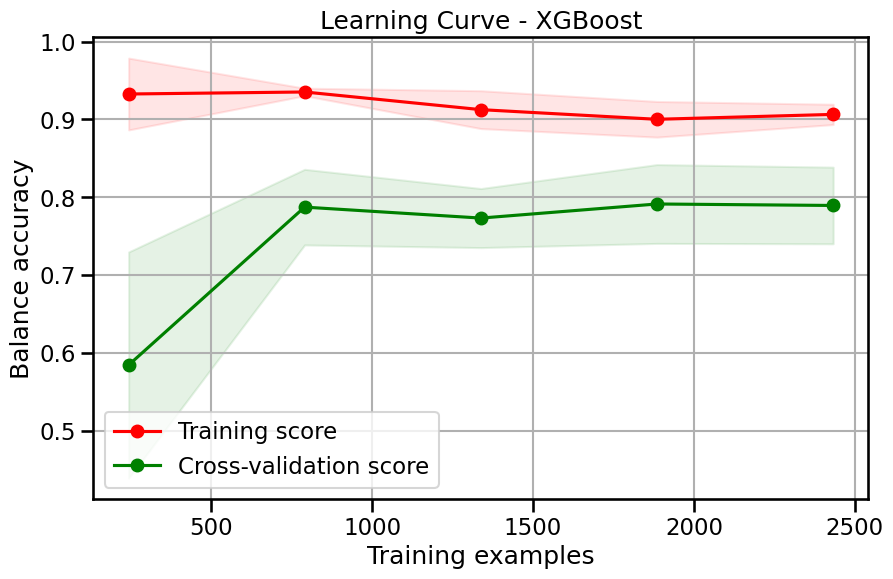

In [ ]:
plot_learning_curve(xgb_model.best_estimator_, "Learning Curve - XGBoost", X, y)

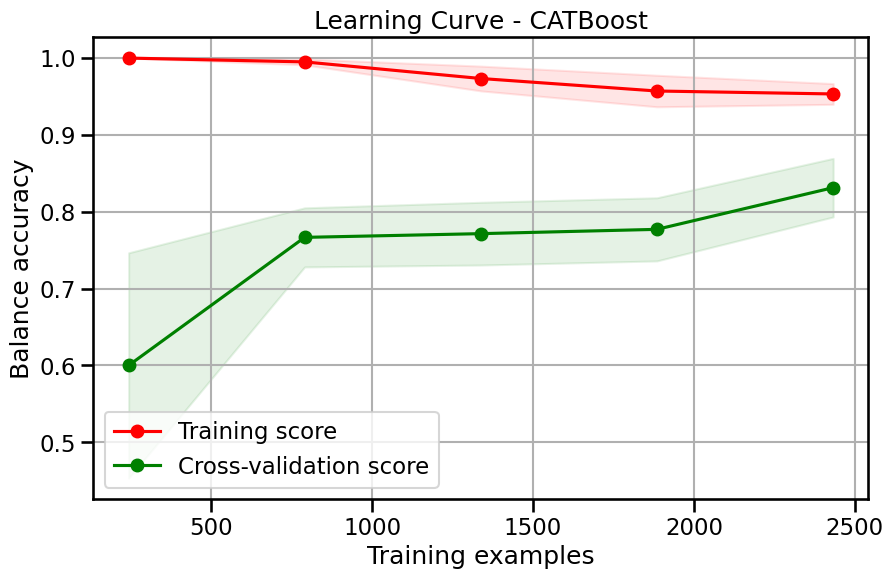

In [ ]:
plot_learning_curve(cat_model.best_estimator_, "Learning Curve - CATBoost", X, y)

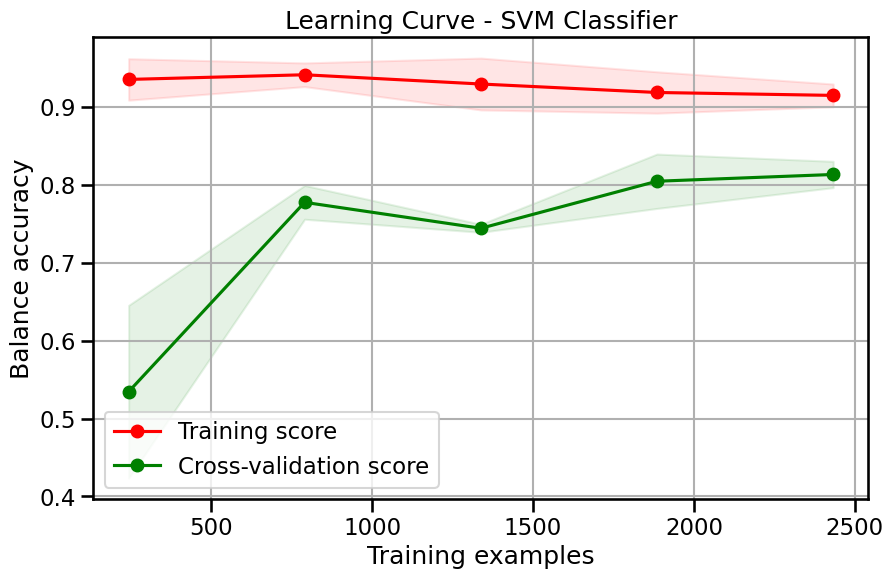

In [ ]:
plot_learning_curve(svm_model.best_estimator_, "Learning Curve - SVM Classifier", X, y)

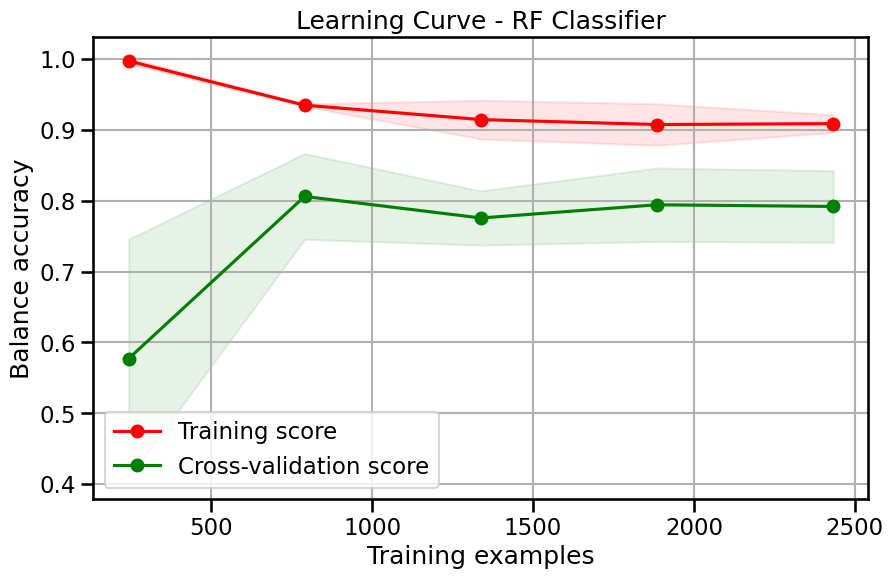

In [ ]:
plot_learning_curve(rf_model.best_estimator_, "Learning Curve - RF Classifier", X, y)

# -------------------Model Performance with Balance Accuracy---------

([0, 1, 2, 3],
 [Text(0, 0, 'Support vector machine'),
  Text(1, 0, 'Cat Boost'),
  Text(2, 0, 'Random forest'),
  Text(3, 0, 'XGBoost')])

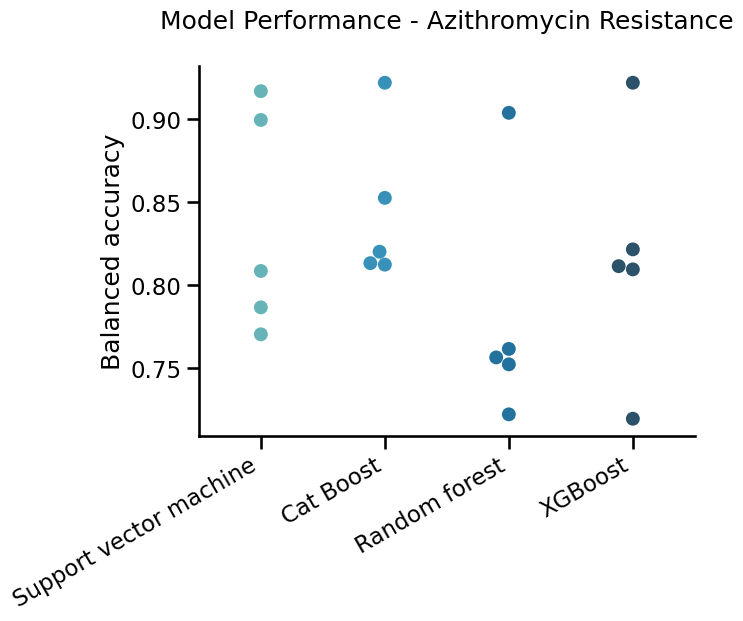

In [ ]:
# compare results from the different predictors
sb.set_context("talk")
plt.title("Model Performance - Azithromycin Resistance", y=1.08)
sb.swarmplot(x=method, y=performance, palette="YlGnBu_d", size=10)
sb.despine()
plt.ylabel("Balanced accuracy")
plt.xticks(rotation=30, ha='right')

# ----------------Model Performance with Training Time------------

([0, 1, 2, 3],
 [Text(0, 0, 'Support vector machine'),
  Text(1, 0, 'Cat Boost'),
  Text(2, 0, 'Random forest'),
  Text(3, 0, 'XGBoost')])

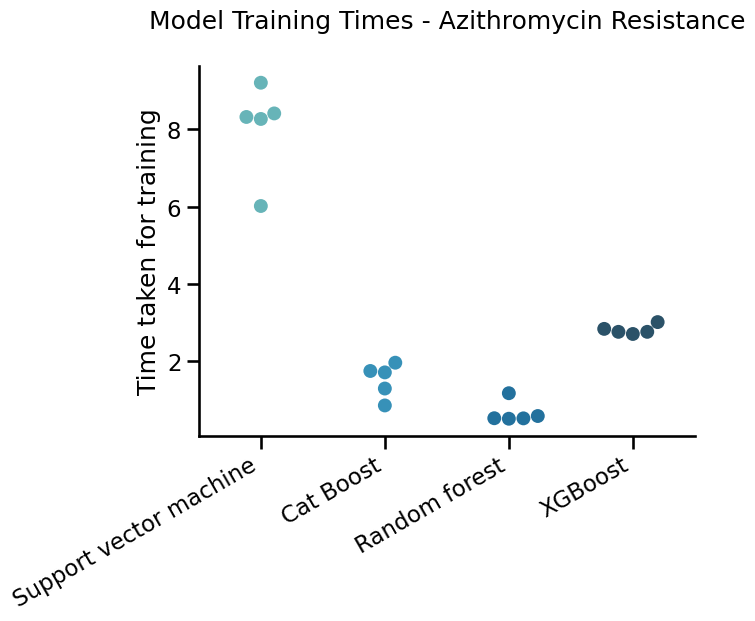

In [ ]:
# took at the time taken to train the different models
sb.set_context("talk")
plt.title("Model Training Times - Azithromycin Resistance", y=1.08)
sb.swarmplot(x=method, y=times, palette="YlGnBu_d", size=10)
sb.despine()
plt.ylabel("Time taken for training")
plt.xticks(rotation=30, ha='right')

In [ ]:
print(rf_model.best_estimator_)
print(svm_model.best_estimator_)
print(xgb_model.best_estimator_)
print(cat_model.best_estimator_.get_params())



RandomForestClassifier(class_weight='balanced', max_depth=3, max_features=258,
                       n_estimators=50, n_jobs=-1, random_state=0)
SVC(C=0.01, class_weight='balanced', gamma=1e-06, kernel='linear',
    probability=True)
XGBClassifier(alpha=1e-05, base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=0.05, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)
{'silent': True, '

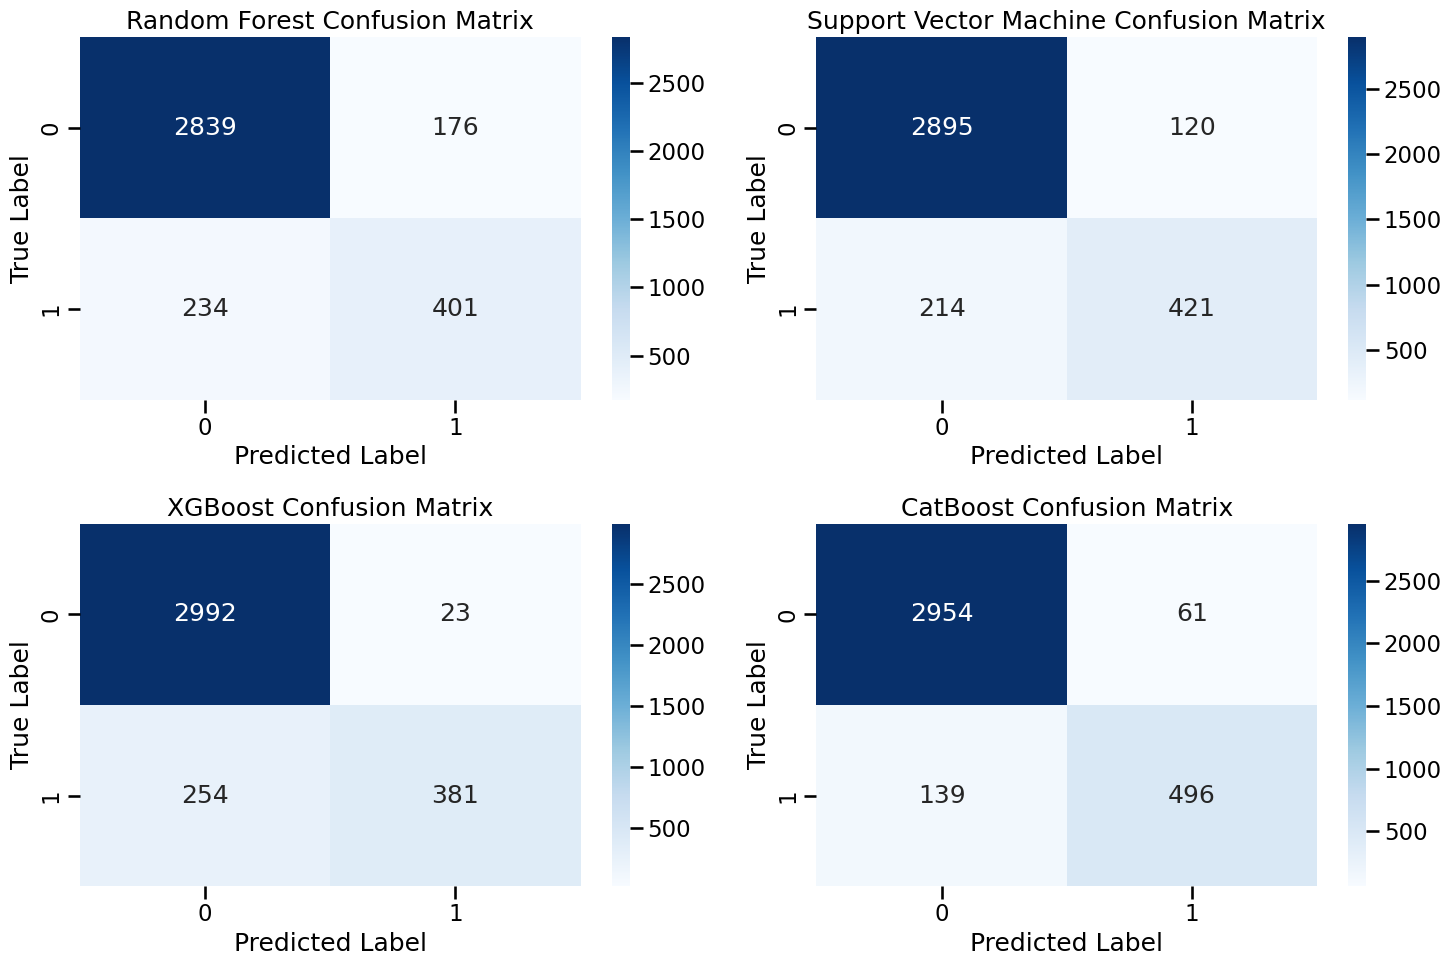

In [ ]:



# Assuming best_rf_model, best_svm_model, best_xgb_model, and best_catboost_model are your trained models

# List of models and their best estimators
models = [
    ('Random Forest', rf_model),
    ('Support Vector Machine', svm_model.best_estimator_),
    ('XGBoost', xgb_model.best_estimator_),
    ('CatBoost', cat_model.best_estimator_)
]

# Set up the plot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

# Plot the confusion matrix for each model
for i, (model_name, model) in enumerate(models):
    # Generate cross-validated predictions
    y_pred = cross_val_predict(model, X, y, cv=5)

    # Compute the confusion matrix
    cm = confusion_matrix(y, y_pred)

    # Plot the confusion matrix
    sb.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i])
    axes[i].set_title(f'{model_name} Confusion Matrix')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()